# Credit Card Fraud Detection - Exploratory Data Analysis & Cleaning

This notebook contains complete code for loading, profiling, cleaning, and visualizing the **Credit Card Fraud Detection** dataset (`creditcard.csv`).

### Goals:
1. **Data Profiling & Cleaning**: Check for missing values, identify duplicates, and ensure proper types.
2. **Exploratory Data Analysis (EDA)**: Visualize class distribution, transaction amounts/times, and key correlations.
3. **Feature Separation Check**: Analyze how standard PCA features separate genuine transactions from fraudulent ones.

## 1. Import Libraries
We import standard data science and visualization libraries (`pandas`, `numpy`, `matplotlib`, and `seaborn`).

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Libraries loaded successfully!")

Libraries loaded successfully!


## 2. Load Dataset
We load `creditcard.csv` and inspect its shape and first few rows.

In [38]:
csv_path = 'creditcard.csv'

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"{csv_path} not found. Please ensure the Kaggle dataset is placed in the project root.")

df = pd.read_csv(csv_path)
print(f"Dataset loaded. Shape: {df.shape[0]:,} rows, {df.shape[1]} columns.")
df.head()

Dataset loaded. Shape: 284,807 rows, 31 columns.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Data Profiling & Cleaning
Before visualizing, we check for null values and duplicate rows, clean any duplicate records, and inspect overall statistical characteristics.

In [39]:
# Check for missing (null) values
null_counts = df.isnull().sum().sum()
print(f"Total missing values: {null_counts}")

# Identify and drop duplicate rows
duplicates = df.duplicated().sum()
print(f"Found {duplicates:,} duplicate rows.")
if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print(f"Duplicates dropped. New shape: {df.shape[0]:,} rows.")

Total missing values: 0
Found 1,081 duplicate rows.
Duplicates dropped. New shape: 283,726 rows.


In [40]:
# Display dataset summary statistics for amount and time
df[['Time', 'Amount']].describe()

,Time,Amount
count,283726.000000,283726.000000
mean,94811.077600,88.472687
std,47481.047891,250.399437
min,0.000000,0.000000
25%,54204.750000,5.600000
50%,84692.500000,22.000000
75%,139298.000000,77.510000
max,172792.000000,25691.160000


## 4. Visualizations & Exploratory Data Analysis

### 4.1 Class Imbalance
Fraud represents only a tiny fraction of card transactions. We visualize this extreme imbalance.

Class Counts:
Genuine (Class 0): 283,253 (99.833%)
Fraudulent (Class 1): 473 (0.167%)


C:\Users\pratik\AppData\Local\Temp\ipykernel_2096\679983235.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Class', data=df, palette=['#10B981', '#EF4444'])


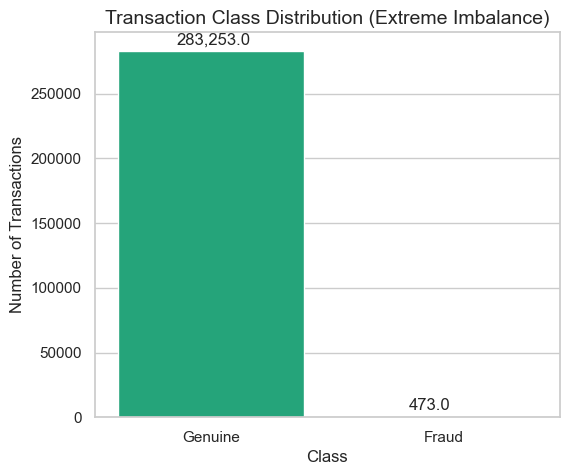

In [41]:
class_counts = df['Class'].value_counts()
print("Class Counts:")
print(f"Genuine (Class 0): {class_counts[0]:,} ({class_counts[0]/len(df)*100:.3f}%)")
print(f"Fraudulent (Class 1): {class_counts[1]:,} ({class_counts[1]/len(df)*100:.3f}%)")

plt.figure(figsize=(6, 5))
ax = sns.countplot(x='Class', data=df, palette=['#10B981', '#EF4444'])
plt.title('Transaction Class Distribution (Extreme Imbalance)', fontsize=14)
plt.xticks(ticks=[0, 1], labels=['Genuine', 'Fraud'])
for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', (p.get_x() + 0.25, p.get_height() + 5000))
plt.ylabel('Number of Transactions')
plt.show()

### 4.2 Transaction Amount Distribution
Let's compare the transaction amounts between genuine and fraudulent card activities. Since fraud amounts tend to cluster differently, we use a log scale plot or boxplot.

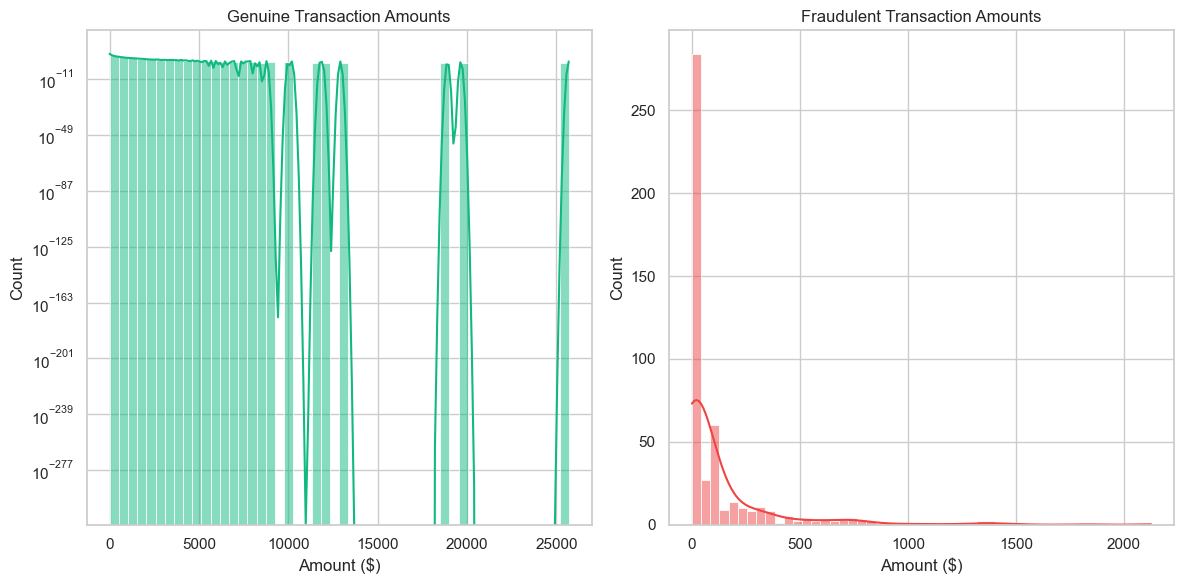

In [42]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, kde=True, color='#10B981', label='Genuine')
plt.title('Genuine Transaction Amounts', fontsize=12)
plt.xlabel('Amount ($)')
plt.yscale('log') # Log scale due to wide outliers

plt.subplot(1, 2, 2)
sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, kde=True, color='#EF4444', label='Fraud')
plt.title('Fraudulent Transaction Amounts', fontsize=12)
plt.xlabel('Amount ($)')

plt.tight_layout()
plt.show()

### 4.3 Transaction Time Analysis
We visualize the transactions relative to elapsed time (seconds from the start of the day) to check if fraud clusters at specific hours.

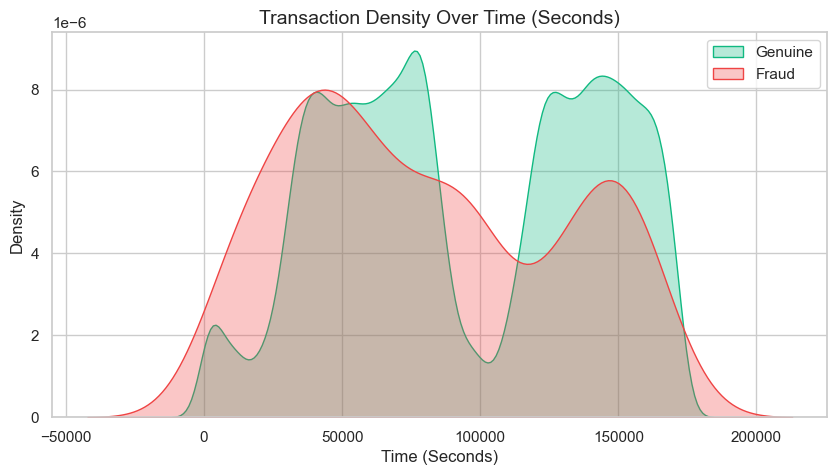

In [43]:
plt.figure(figsize=(10, 5))
sns.kdeplot(df[df['Class'] == 0]['Time'], color='#10B981', fill=True, alpha=0.3, label='Genuine')
sns.kdeplot(df[df['Class'] == 1]['Time'], color='#EF4444', fill=True, alpha=0.3, label='Fraud')
plt.title('Transaction Density Over Time (Seconds)', fontsize=14)
plt.xlabel('Time (Seconds)')
plt.ylabel('Density')
plt.legend()
plt.show()

### 4.4 Correlation Analysis
We construct a correlation matrix to identify which variables show strong linear dependencies with our target `Class` column.

Strongest Negative Correlations:
V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
Name: Class, dtype: float64

Strongest Positive Correlations:
V8     0.033068
V19    0.033631
V2     0.084624
V4     0.129326
V11    0.149067
Name: Class, dtype: float64


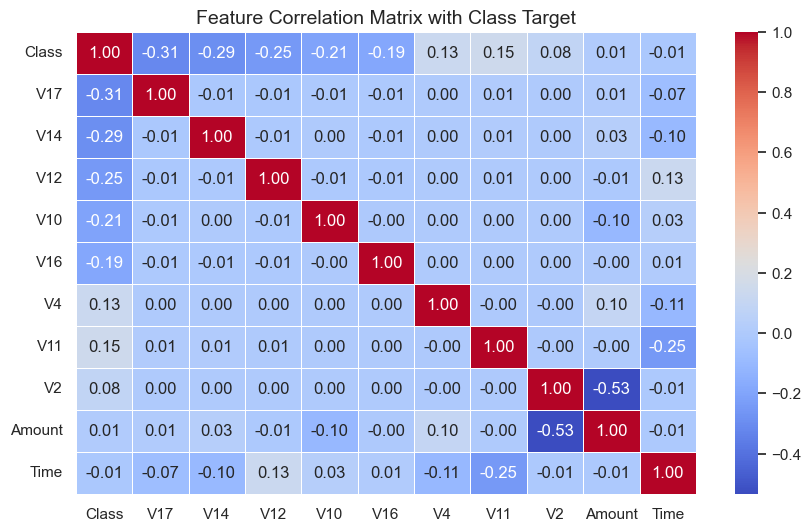

In [44]:
# Compute correlation of features with Class column
correlations = df.corr()['Class'].sort_values()

print("Strongest Negative Correlations:")
print(correlations.head(5))
print("\nStrongest Positive Correlations:")
print(correlations.tail(6).iloc[:-1]) # omit Class self-correlation

# Heatmap for key correlated features
key_features = ['Class', 'V17', 'V14', 'V12', 'V10', 'V16', 'V4', 'V11', 'V2', 'Amount', 'Time']
sns.heatmap(df[key_features].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Matrix with Class Target', fontsize=14)
plt.show()

### 4.5 Class Separation of Key Correlated Features
Let's look at boxplots of features like `V14`, `V17`, `V4`, and `V11` to inspect how cleanly their distributions differ for genuine vs. fraudulent transactions.

C:\Users\pratik\AppData\Local\Temp\ipykernel_2096\258386972.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='V14', data=df, ax=axes[0, 0], palette=['#10B981', '#EF4444'])
C:\Users\pratik\AppData\Local\Temp\ipykernel_2096\258386972.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Genuine', 'Fraud'])
C:\Users\pratik\AppData\Local\Temp\ipykernel_2096\258386972.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='V17', data=df, ax=axes[0, 1], palette=['#10B981', '#EF4444'])
C:\Users\pratik\AppData\Local\Temp\ipykernel_2096\258386972.py:11: UserWarnin

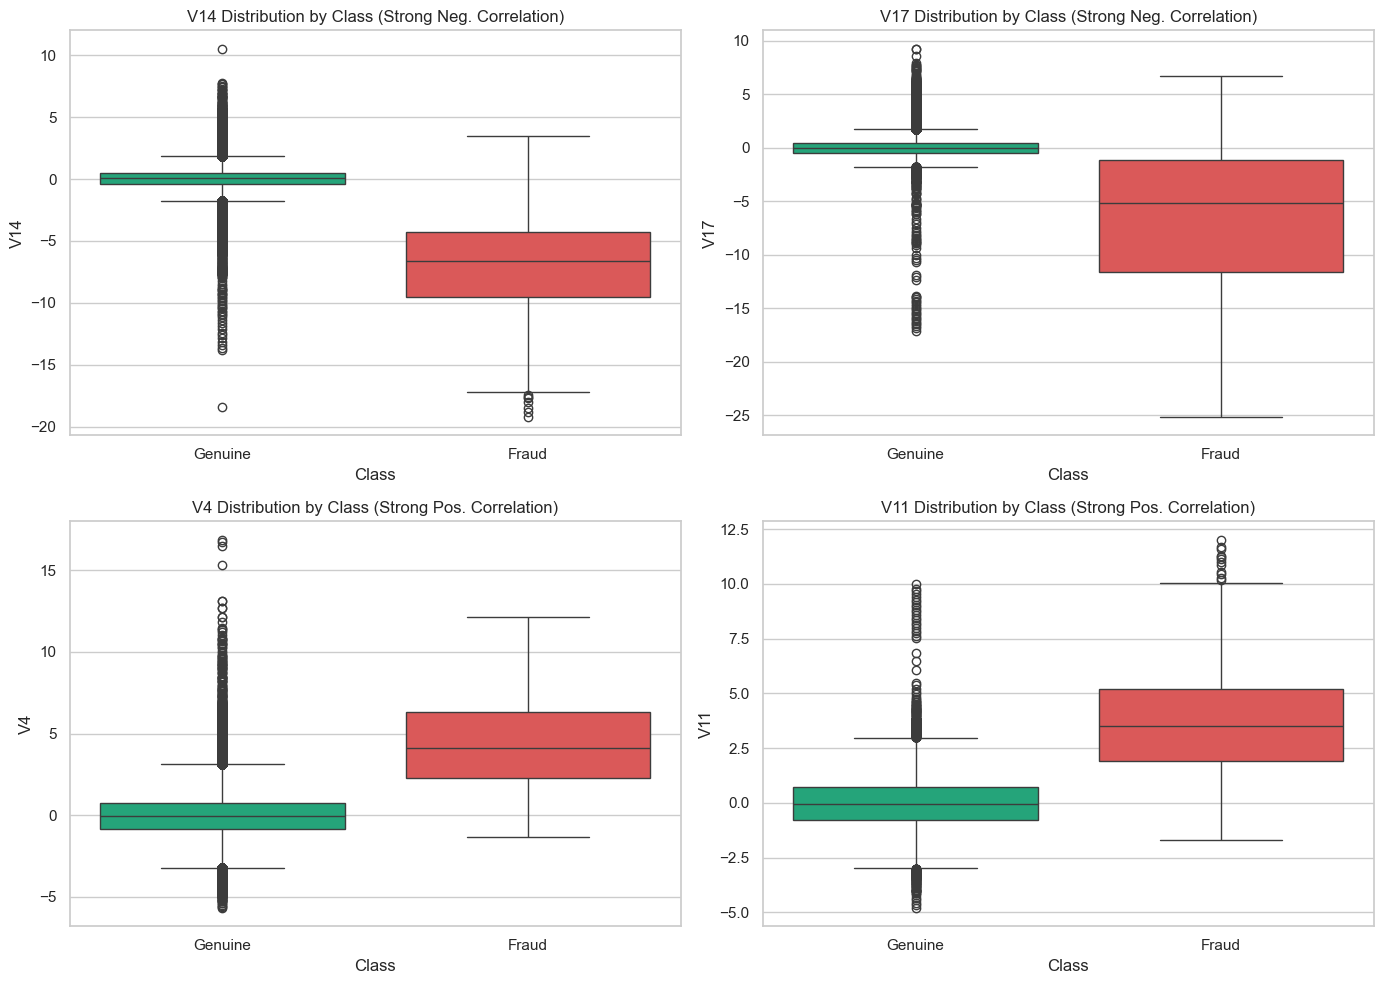

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# V14 Boxplot
sns.boxplot(x='Class', y='V14', data=df, ax=axes[0, 0], palette=['#10B981', '#EF4444'])
axes[0, 0].set_title('V14 Distribution by Class (Strong Neg. Correlation)', fontsize=12)
axes[0, 0].set_xticklabels(['Genuine', 'Fraud'])

# V17 Boxplot
sns.boxplot(x='Class', y='V17', data=df, ax=axes[0, 1], palette=['#10B981', '#EF4444'])
axes[0, 1].set_title('V17 Distribution by Class (Strong Neg. Correlation)', fontsize=12)
axes[0, 1].set_xticklabels(['Genuine', 'Fraud'])

# V4 Boxplot
sns.boxplot(x='Class', y='V4', data=df, ax=axes[1, 0], palette=['#10B981', '#EF4444'])
axes[1, 0].set_title('V4 Distribution by Class (Strong Pos. Correlation)', fontsize=12)
axes[1, 0].set_xticklabels(['Genuine', 'Fraud'])

# V11 Boxplot
sns.boxplot(x='Class', y='V11', data=df, ax=axes[1, 1], palette=['#10B981', '#EF4444'])
axes[1, 1].set_title('V11 Distribution by Class (Strong Pos. Correlation)', fontsize=12)
axes[1, 1].set_xticklabels(['Genuine', 'Fraud'])

plt.tight_layout()
plt.show()

### Conclusion of Analysis
*   The dataset displays a massive imbalance which requires robust handling (using class weights, metrics like Recall/Precision rather than Accuracy).
*   Features `V14`, `V17`, `V12`, `V10` exhibit strongly shifted negative distributions during fraud instances, which makes them critical inputs for our Random Forest model to block fraudulent card requests.